<a href="https://colab.research.google.com/github/leopapuma/modelo-sir/blob/main/modelo_sir_con_metropolis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**modelo sir con metropolis**

usuaremos este sistemas de ecuaciones diferenciales
\begin{aligned}
\frac{dS}{dt}&=-aSI \\
\frac{dI}{dt}&=aSI-bI \\
\frac{dR}{dt}&=bI
\end{aligned}
Donde:
- \(S\): personas susceptibles.
- \(I\): personas infectadas.
- \(R\): personas recuperadas.
- \(a\): tasa de transmisión.
- \(b\): tasa de recuperación.


usuaremos las siguintes librerias

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from scipy.special import gammaln

np.random.seed(42) #aqui fijamos la semila para tener los resultados

comensamos dando datos para resolver el problema

In [4]:
# aqui colocareemos 14 dias para observar el comportamiento
dias = np.arange(15)

# colocamos el numero infectados observados
infectados_obs = np.array([
    1, 3, 6, 25, 73, 222, 294,
    258, 237, 191, 125, 69, 27, 11, 4
])

# tendremos una poblacion total de 763
N = 763

# daremos las condiciones iniciales
I0 = 1 #comensamos con una persona infectada
S0 = N - I0 # las demas personas son suseptibles
R0 = 0 #suponemos que no hay personas recuperadas

construimos las ecuaciones del sir

In [6]:
def modelo_SIR(y, t, a, b): #construimos la funcion con las variables del modelo que vamos usar
    S, I, R = y

    dS = -a * S * I #calculamos la tasa de disminución de susceptibles.
    dI = a * S * I - b * I #calculamos el cambio neto de infectados
    dR = b * I #calculamos la tasa de variacion

    return [dS, dI, dR]

resolvemos el modelo numericamente

In [8]:
def simular_SIR(a, b): #construimos la funcion con los dos parametros que queremos encontrar que es a y b
    condiciones_iniciales = [S0, I0, R0]

    solucion = odeint( #aqui se resolvera el sistema de ecuaciones
        modelo_SIR,
        condiciones_iniciales,
        dias,
        args=(a, b)
    )

    S = solucion[:, 0] #aqui extraemos la columna de susceptibles
    I = solucion[:, 1] #estremos la columna de infectados
    R = solucion[:, 2] # extraemos la columna de recuperados

    return S, I, R

defenimos la verosimilitud  
usuando la sig formula:
\begin{aligned}
\[ L(a,b)=\prod_{t=0}^{14} \frac{e^{-\mu_t}\mu_t^{y_t}}{y_t!} \]
\end{aligned}


In [9]:
def log_verosimilitud(a, b):

    # vamos a simular eñ modelo con los parametros propuestos a y b
    _, I_modelo, _ = simular_SIR(a, b)

    # aqui vamos evitar el logaritmo de cero
    mu = np.maximum(I_modelo, 1e-10)

    # Calculamos el log-verosimilitud de Poisson
    logL = np.sum(
        infectados_obs * np.log(mu)
        - mu
        - gammaln(infectados_obs + 1)
    )

    return logL

defenimos la funcions posterior

In [10]:
def log_posterior(a, b):

    # se vereficaran  que los parametros esten dentro de los limites
    if not (0 < a < 0.01 and 0 < b < 1):
        return -np.inf

    # Distribucion previa uniforme dentro de los limites
    return log_verosimilitud(a, b)

ahora implementaremos el algoritmo de metropolis

In [12]:
# Numero total de iteraciones
n_iter = 30000

# Iteraciones iniciales que descartaremos
burn_in = 5000

# Matriz para almacenar las muestras de a y b
cadena = np.zeros((n_iter, 2))

# Valores iniciales de los parametros
a_actual = 0.002
b_actual = 0.4

# Evaluar la posterior inicial
logp_actual = log_posterior(a_actual, b_actual)

# Contador de propuestas aceptadas
aceptados = 0

# Iniciar el algoritmo
for i in range(n_iter):

    # Proponemos nuevos valores mediante distribuciones normales
    a_nuevo = np.random.normal(a_actual, 0.00015)
    b_nuevo = np.random.normal(b_actual, 0.04)

    # Evaluamos la posterior de la propuesta
    logp_nuevo = log_posterior(a_nuevo, b_nuevo)

    # Diferencia entre las log-posteriores
    diferencia = logp_nuevo - logp_actual

    # aplicamos la Regla de aceptacion de Metropolis
    if np.log(np.random.rand()) < min(0, diferencia):

        a_actual = a_nuevo
        b_actual = b_nuevo

        logp_actual = logp_nuevo

        aceptados += 1

    # Guardamos los valores actuales de la cadena
    cadena[i, 0] = a_actual
    cadena[i, 1] = b_actual

# Calculamoa la proporcion de aceptacion
tasa_aceptacion = aceptados / n_iter

print("Tasa de aceptacion:", tasa_aceptacion)

Tasa de aceptacion: 0.06283333333333334


obtenemos la estimaciones de los parametros

In [13]:
# Eliminaremos las primeras iteraciones
muestras = cadena[burn_in:, :]

# Separamos las columnas
a_muestras = muestras[:, 0]
b_muestras = muestras[:, 1]

# Estimaciones puntuales mediante la mediana
a_estimado = np.median(a_muestras)
b_estimado = np.median(b_muestras)

print("Estimacion de a:", a_estimado)
print("Estimacion de b:", b_estimado)

# Intervalos posteriores centrales del 95%
intervalo_a = np.percentile(a_muestras, [2.5, 97.5])
intervalo_b = np.percentile(b_muestras, [2.5, 97.5])

print("Intervalo del 95% de a:", intervalo_a)
print("Intervalo del 95% de b:", intervalo_b)

Estimacion de a: 0.002211346915018264
Estimacion de b: 0.48150024889560633
Intervalo del 95% de a: [0.00217224 0.0022505 ]
Intervalo del 95% de b: [0.45991237 0.50289945]


se obtuvo a=0.002211 que significa ños nuevos contagios que puede ver, b=0.4815 es la tasa de recuperacion que estubieron infectados

graficamos las cadenas metropolis

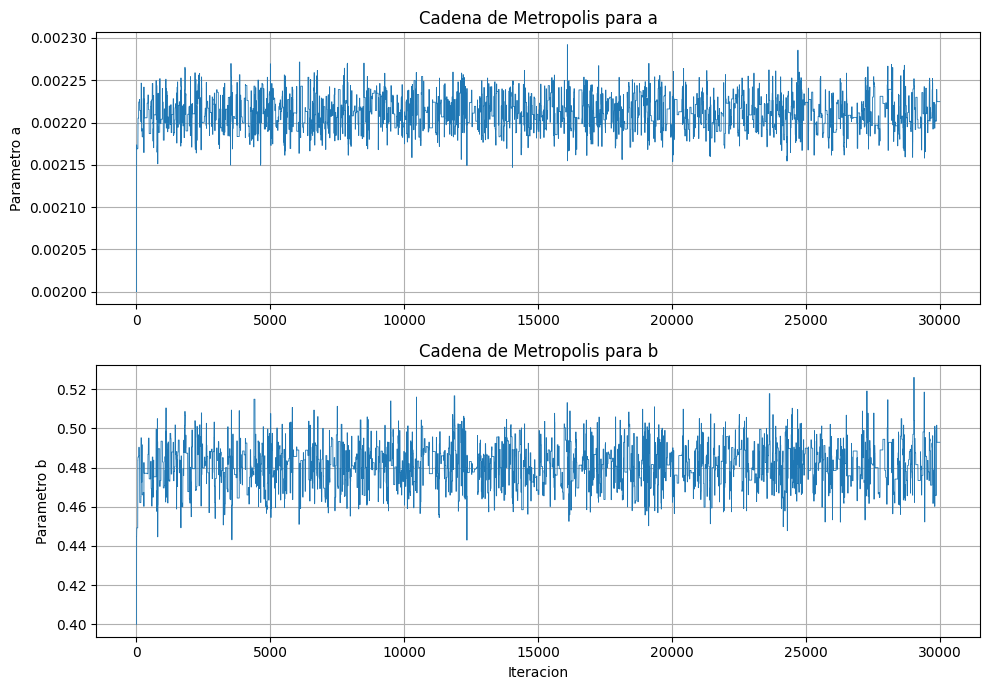

In [14]:
fig, ax = plt.subplots(2, 1, figsize=(10, 7))

ax[0].plot(cadena[:, 0], linewidth=0.6)
ax[0].set_title("Cadena de Metropolis para a")
ax[0].set_ylabel("Parametro a")
ax[0].grid(True)

ax[1].plot(cadena[:, 1], linewidth=0.6)
ax[1].set_title("Cadena de Metropolis para b")
ax[1].set_xlabel("Iteracion")
ax[1].set_ylabel("Parametro b")
ax[1].grid(True)

plt.tight_layout()
plt.show()

comparamos el modelo ajustado con los datos que dimos

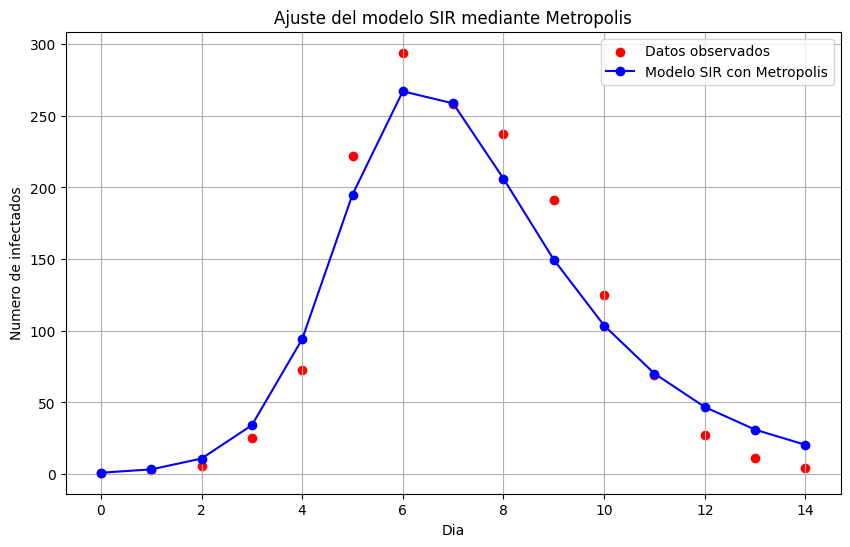

Parametro a estimado: 0.002211346915018264
Parametro b estimado: 0.48150024889560633
Numero reproductivo inicial aproximado: 3.4995752403219442


In [16]:
# Simulamos el modelo con los parametros estimados
S_est, I_est, R_est = simular_SIR(a_estimado, b_estimado)

# Creamos  la grafica
plt.figure(figsize=(10, 6))

# Datos reales
plt.scatter(
    dias,
    infectados_obs,
    color="red",
    label="Datos observados"
)

# Predicciones del modelo
plt.plot(
    dias,
    I_est,
    color="blue",
    marker="o",
    label="Modelo SIR con Metropolis"
)

plt.xlabel("Dia")
plt.ylabel("Numero de infectados")
plt.title("Ajuste del modelo SIR mediante Metropolis")

plt.legend()
plt.grid(True)
plt.show()

print("Parametro a estimado:", a_estimado)
print("Parametro b estimado:", b_estimado)


R_efectivo_inicial = a_estimado * S0 / b_estimado

print("Numero reproductivo inicial aproximado:",
      R_efectivo_inicial)

los puntos rojos son los infectados observados, y la curva azul son los infectados predichos con el modelo, se puede observar que hay una distancia entre la curva y los puntos.